# Employee Attrition Prediction

A machine learning project that predicts whether an employee is likely to
leave a company ("attrition"), based on HR attributes such as age, income,
overtime, job satisfaction, and tenure.

**Dataset:** `dataset.csv` (1,470 employees, 35 columns — IBM HR Analytics
Employee Attrition dataset).

**Tools:** pandas, numpy, matplotlib, seaborn, scikit-learn (no deep
learning / no external APIs).

**Workflow:**
1. Data loading & understanding
2. Exploratory data analysis (EDA)
3. Preprocessing (cleaning, encoding, scaling, train/test split)
4. Feature selection
5. Training multiple classification models
6. Model evaluation
7. Feature importance analysis
8. A simple prediction function
9. Final insights & retention recommendations


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
%matplotlib inline


def clean_feature_name(name):
    """Strip the ColumnTransformer prefix (e.g. 'num__Age' -> 'Age') for readable output."""
    return name.split("__", 1)[-1] if "__" in name else name

## Step 1: Data Loading & Understanding

In [2]:
df = pd.read_csv("dataset.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))

Shape (rows, columns): (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [4]:
df.dtypes

Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours                int64
StockOptionLevel             int64
TotalWorkingYears   

In [5]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found.")

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
No missing values found.

Duplicate rows: 0


In [6]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [7]:
print(df["Attrition"].value_counts())
print()
print((df["Attrition"].value_counts(normalize=True) * 100).round(1), "(%)")

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition
No     83.9
Yes    16.1
Name: proportion, dtype: float64 (%)


**Observations:** The dataset has 1,470 employees and 35 columns, with
**no missing values and no duplicate rows** — so no imputation is required.
The target `Attrition` is **imbalanced**: about 84% "No" vs 16% "Yes". This
means accuracy alone will be a misleading metric later — a model that
always predicts "No" would already score ~84% accuracy while being useless
for identifying employees at risk.

## Step 2: Exploratory Data Analysis

Only the plots that provide clear, useful insight into attrition are shown below.

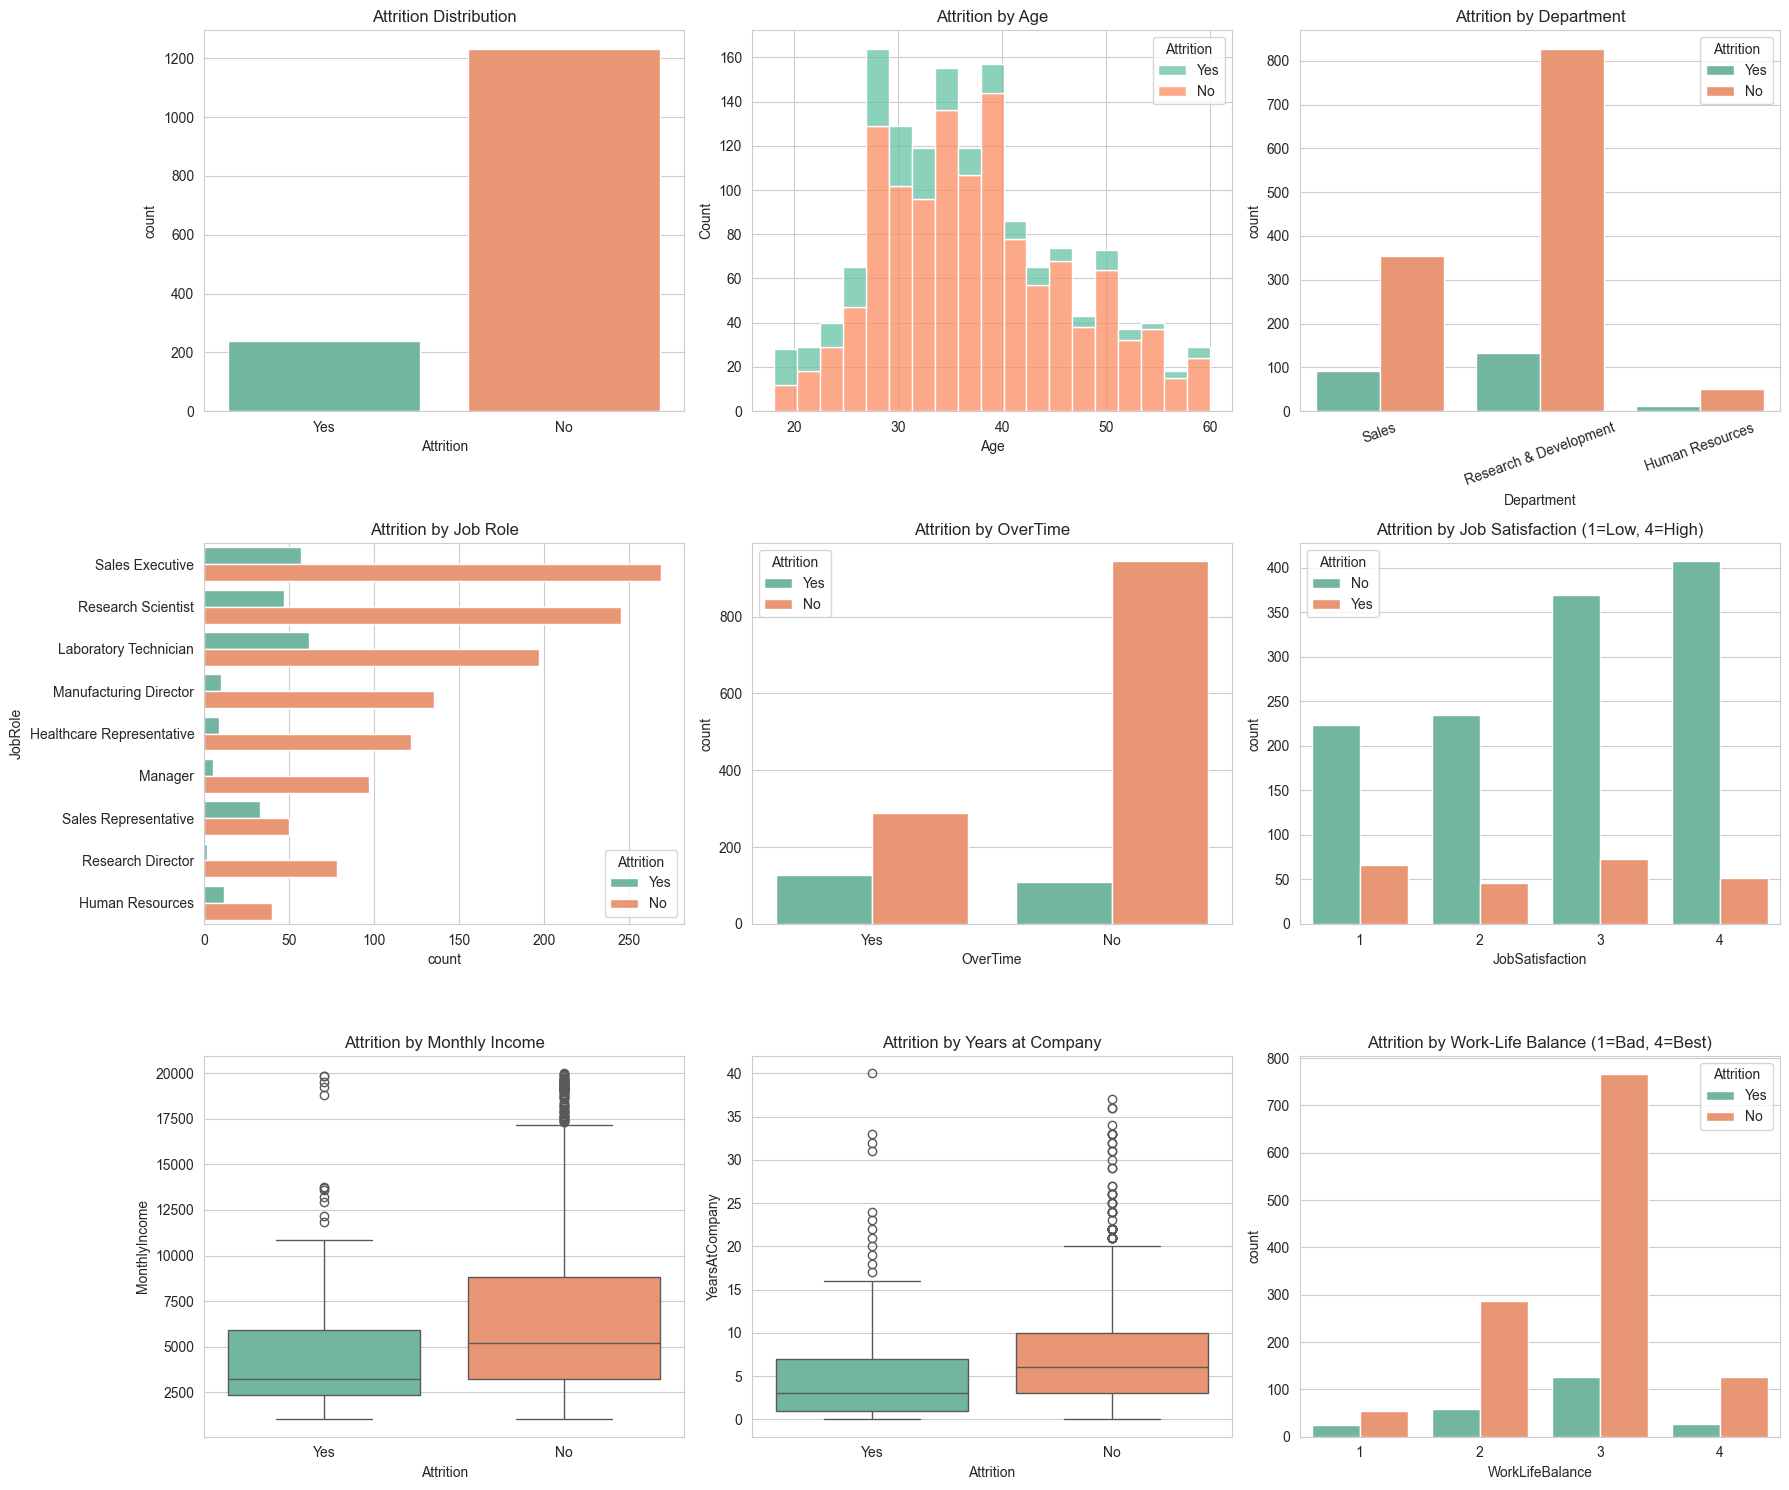

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))

# 1. Attrition distribution
sns.countplot(data=df, x="Attrition", hue="Attrition", palette="Set2", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Attrition Distribution")

# 2. Attrition by age
sns.histplot(data=df, x="Age", hue="Attrition", multiple="stack", palette="Set2", ax=axes[0, 1])
axes[0, 1].set_title("Attrition by Age")

# 3. Attrition by department
sns.countplot(data=df, x="Department", hue="Attrition", palette="Set2", ax=axes[0, 2])
axes[0, 2].set_title("Attrition by Department")
axes[0, 2].tick_params(axis="x", rotation=20)

# 4. Attrition by job role
role_order = df["JobRole"].value_counts().index
sns.countplot(data=df, y="JobRole", hue="Attrition", palette="Set2", order=role_order, ax=axes[1, 0])
axes[1, 0].set_title("Attrition by Job Role")

# 5. Attrition by overtime
sns.countplot(data=df, x="OverTime", hue="Attrition", palette="Set2", ax=axes[1, 1])
axes[1, 1].set_title("Attrition by OverTime")

# 6. Attrition by job satisfaction
sns.countplot(data=df, x="JobSatisfaction", hue="Attrition", palette="Set2", ax=axes[1, 2])
axes[1, 2].set_title("Attrition by Job Satisfaction (1=Low, 4=High)")

# 7. Attrition by monthly income
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", hue="Attrition", palette="Set2", legend=False, ax=axes[2, 0])
axes[2, 0].set_title("Attrition by Monthly Income")

# 8. Attrition by years at company
sns.boxplot(data=df, x="Attrition", y="YearsAtCompany", hue="Attrition", palette="Set2", legend=False, ax=axes[2, 1])
axes[2, 1].set_title("Attrition by Years at Company")

# 9. Attrition by work-life balance
sns.countplot(data=df, x="WorkLifeBalance", hue="Attrition", palette="Set2", ax=axes[2, 2])
axes[2, 2].set_title("Attrition by Work-Life Balance (1=Bad, 4=Best)")

plt.tight_layout()
plt.show()

**EDA takeaways:**
- Employees who work **overtime** leave at a much higher *rate* than those who don't, even though non-overtime employees are the majority group.
- **Younger employees** (roughly 18-30) show visibly higher attrition than mid-career and senior employees.
- **Low job satisfaction (1)** and **poor work-life balance (1)** are both associated with a higher proportion of attrition compared to the higher-rated categories.
- Employees who leave tend to have **lower monthly income** and **fewer years at the company** (medians are visibly lower in the boxplots) — i.e. attrition is concentrated among newer, lower-paid employees.
- **Sales Representative** and **Laboratory Technician** roles show a higher attrition share relative to their group size than roles like Manager or Research Director.

## Step 3: Preprocessing

Steps taken:
1. Drop columns that are identifiers or constant (no predictive signal).
2. Check for redundant/highly correlated numeric features.
3. Encode the target (`Yes` → 1, `No` → 0).
4. Split into train/test **before** fitting any encoder or scaler, to avoid data leakage.
5. Build a `ColumnTransformer` (one-hot encode categoricals + scale numerics) that is fit only on the training data.

In [9]:
data = df.copy()

# Columns that are identifiers or carry no predictive information:
# - EmployeeNumber: a unique ID per employee, not a real attribute.
# - EmployeeCount and StandardHours: constant for every row (zero variance -> no signal).
# - Over18: constant ('Y' for every employee) -> no signal.
cols_to_drop = ["EmployeeNumber", "EmployeeCount", "StandardHours", "Over18"]
print(f"Dropping identifier/constant columns: {cols_to_drop}")
data = data.drop(columns=cols_to_drop)

Dropping identifier/constant columns: ['EmployeeNumber', 'EmployeeCount', 'StandardHours', 'Over18']


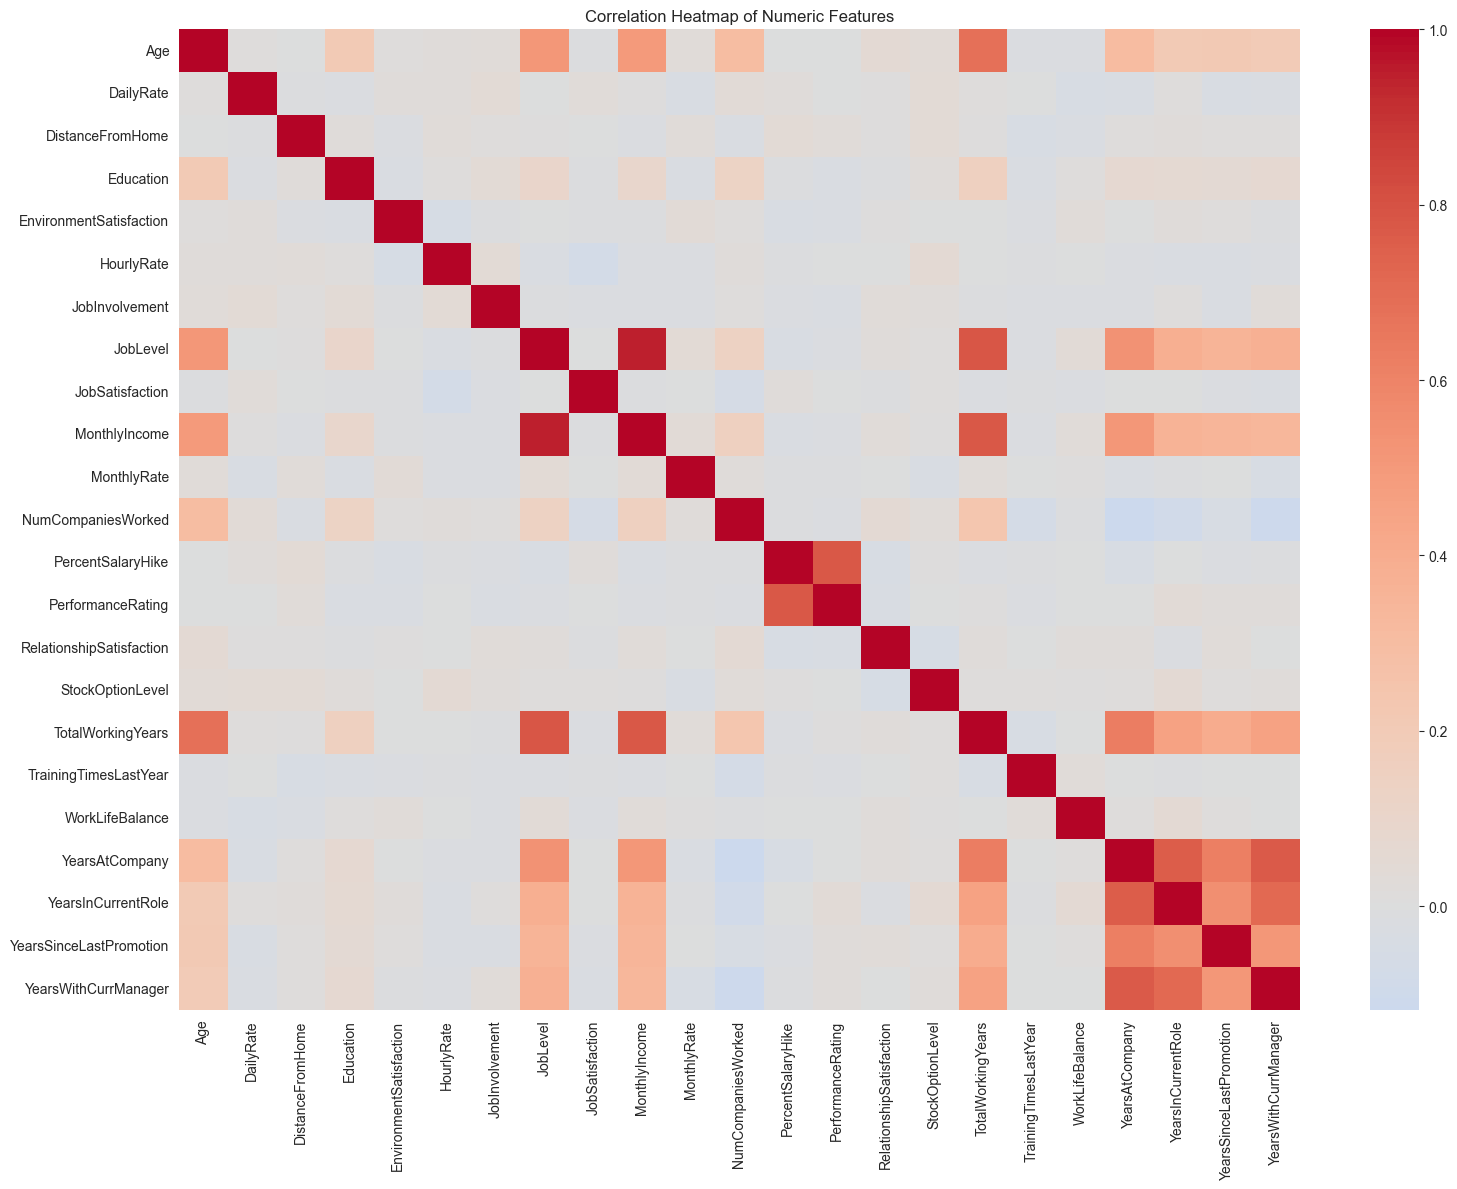

In [10]:
numeric_preview = data.select_dtypes(include="number")
corr_matrix = numeric_preview.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

In [11]:
high_corr_pairs = (
    corr_matrix.abs()
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)
print("Highly correlated numeric feature pairs (|r| > 0.7):")
print(high_corr_pairs[high_corr_pairs > 0.7])

Highly correlated numeric feature pairs (|r| > 0.7):
JobLevel            MonthlyIncome           0.950300
                    TotalWorkingYears       0.782208
PercentSalaryHike   PerformanceRating       0.773550
MonthlyIncome       TotalWorkingYears       0.772893
YearsAtCompany      YearsWithCurrManager    0.769212
                    YearsInCurrentRole      0.758754
YearsInCurrentRole  YearsWithCurrManager    0.714365
dtype: float64


`JobLevel` is almost a duplicate of `MonthlyIncome` (r ≈ 0.95) and also
overlaps heavily with `TotalWorkingYears` (r ≈ 0.78). Keeping both
`JobLevel` and `MonthlyIncome` would add redundant, collinear information
without adding new signal, so **`JobLevel` is dropped** — `MonthlyIncome`
is kept because it is more directly interpretable for a retention story.
The other pairs (e.g. `YearsAtCompany` vs `YearsWithCurrManager`) are
moderately correlated but capture genuinely different aspects of tenure, so
they are kept.

In [12]:
data = data.drop(columns=["JobLevel"])
print("Missing values after cleanup:", data.isnull().sum().sum())

# Encode target: Yes -> 1, No -> 0
data["Attrition"] = data["Attrition"].map({"Yes": 1, "No": 0})

X = data.drop(columns=["Attrition"])
y = data["Attrition"]

categorical_cols = X.select_dtypes(include="object").columns.tolist()
numerical_cols = X.select_dtypes(include="number").columns.tolist()
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")

Missing values after cleanup: 0
Categorical columns (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numerical columns (22): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [13]:
# Train/test split BEFORE fitting any encoder/scaler -> avoids data leakage.
# stratify=y keeps the same Yes/No ratio in both splits, important since the
# target is imbalanced (~84% No vs ~16% Yes).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (1176, 29), Test shape: (294, 29)


In [14]:
# ColumnTransformer: one-hot encode categoricals, standard-scale numerics.
# drop='first' avoids the dummy-variable trap (perfect multicollinearity).
# It is fit only inside each model's Pipeline.fit(X_train, ...) later on, so
# the encoder/scaler statistics never see the test set.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
    ]
)

## Step 4: Feature Selection

Two simple, explainable methods are used:
1. **Random Forest feature importance** — how much each feature reduces impurity across all trees.
2. **SelectKBest (ANOVA F-test)** — a univariate statistical test scoring each feature's individual relationship with the target.

Both are fit on the **training data only**.

In [15]:
preprocessor_fitted = preprocessor.fit(X_train, y_train)
feature_names = preprocessor_fitted.get_feature_names_out()
X_train_proc = pd.DataFrame(preprocessor_fitted.transform(X_train), columns=feature_names)

rf_probe = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced")
rf_probe.fit(X_train_proc, y_train)
rf_importance = pd.Series(rf_probe.feature_importances_, index=feature_names).sort_values(ascending=False)
rf_importance_clean = rf_importance.rename(index=clean_feature_name)
print("Top 15 features by Random Forest importance:")
rf_importance_clean.head(15)

Top 15 features by Random Forest importance:


MonthlyIncome              0.072141
Age                        0.066958
TotalWorkingYears          0.058298
DailyRate                  0.051753
YearsAtCompany             0.048413
DistanceFromHome           0.047209
MonthlyRate                0.046373
HourlyRate                 0.043665
YearsWithCurrManager       0.043068
OverTime_Yes               0.041975
NumCompaniesWorked         0.037659
PercentSalaryHike          0.034285
YearsInCurrentRole         0.033302
StockOptionLevel           0.032377
EnvironmentSatisfaction    0.027334
dtype: float64

In [16]:
K_BEST = 20
selector = SelectKBest(score_func=f_classif, k=K_BEST)
selector.fit(X_train_proc, y_train)
selected_mask = selector.get_support()
selected_features = feature_names[selected_mask]
print(f"Top {K_BEST} features selected by SelectKBest (ANOVA F-test):")
print([clean_feature_name(f) for f in selected_features])

overlap = set(rf_importance.head(K_BEST).index) & set(selected_features)
print(f"\nOverlap between RF top-{K_BEST} and SelectKBest top-{K_BEST}: {len(overlap)}/{K_BEST} features")

Top 20 features selected by SelectKBest (ANOVA F-test):
['Age', 'DistanceFromHome', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'MonthlyIncome', 'StockOptionLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager', 'BusinessTravel_Travel_Frequently', 'Department_Research & Development', 'JobRole_Laboratory Technician', 'JobRole_Manufacturing Director', 'JobRole_Research Director', 'JobRole_Sales Representative', 'MaritalStatus_Married', 'MaritalStatus_Single', 'OverTime_Yes']

Overlap between RF top-20 and SelectKBest top-20: 11/20 features


Both methods agree strongly on features like `MonthlyIncome`, `Age`,
`TotalWorkingYears`, `OverTime`, tenure-related columns, and
`StockOptionLevel` — these are the ones most predictive of attrition. The
final models below are trained on the **top 20 SelectKBest features**
(reduced from 42 encoded features), which keeps the models simpler and
removes noisy, low-signal columns without sacrificing performance.

## Step 5: Train Multiple Models

Each model gets its own `Pipeline`: preprocess → select top-K features →
classify. Wrapping everything in one `Pipeline` means `.fit()` only ever
learns from `X_train`, and the same fitted steps are reused automatically
for `X_test` (no leakage), which also makes the prediction function in
Step 8 trivial.

Because the target is imbalanced, `class_weight="balanced"` is used for
Logistic Regression, Decision Tree and Random Forest (KNN has no such
option).

In [17]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=10, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=9),
}

pipelines = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(
        steps=[
            ("preprocess", preprocessor),
            ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
            ("model", estimator),
        ]
    )
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        }
    )
    pipelines[name] = pipe

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.7653,0.3750,0.7021,0.4889
Decision Tree,0.7381,0.3333,0.6383,0.4380
Random Forest,0.8401,0.5000,0.1489,0.2295
K-Nearest Neighbors,0.8537,0.8333,0.1064,0.1887


In [18]:
# Because the target is imbalanced (~84% No / ~16% Yes), the best model is
# chosen by F1-score (balances precision and recall) rather than accuracy,
# which would be misleadingly high for a model that just predicts "No" often.
best_model_name = results_df["F1-Score"].idxmax()
best_pipeline = pipelines[best_model_name]
print(f"Best performing model (highest F1-score): {best_model_name}")

Best performing model (highest F1-score): Logistic Regression


**Why F1, not accuracy?** Random Forest and KNN post the *highest
accuracy* in the table above, but their *recall* on the "Leave" class is
very low — they mostly predict "No" and coast on the 84% majority class,
missing most of the employees who actually leave. Logistic Regression has
lower raw accuracy but a much higher recall (it catches far more actual
leavers), giving it the best F1-score. In an HR retention context, missing
an at-risk employee (a false negative) is usually costlier than a false
alarm, so F1/recall matter more than accuracy here.

## Step 6: Model Evaluation — Best Model

In [19]:
y_pred_best = best_pipeline.predict(X_test)
y_proba_best = best_pipeline.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred_best)
prec = precision_score(y_test, y_pred_best, zero_division=0)
rec = recall_score(y_test, y_pred_best, zero_division=0)
f1 = f1_score(y_test, y_pred_best, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba_best)

print(f"Model     : {best_model_name}")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print()
print("Classification report:")
print(classification_report(y_test, y_pred_best, target_names=["No (Stay)", "Yes (Leave)"]))

Model     : Logistic Regression
Accuracy  : 0.7653
Precision : 0.3750
Recall    : 0.7021
F1-Score  : 0.4889
ROC-AUC   : 0.7801

Classification report:
              precision    recall  f1-score   support

   No (Stay)       0.93      0.78      0.85       247
 Yes (Leave)       0.38      0.70      0.49        47

    accuracy                           0.77       294
   macro avg       0.65      0.74      0.67       294
weighted avg       0.84      0.77      0.79       294



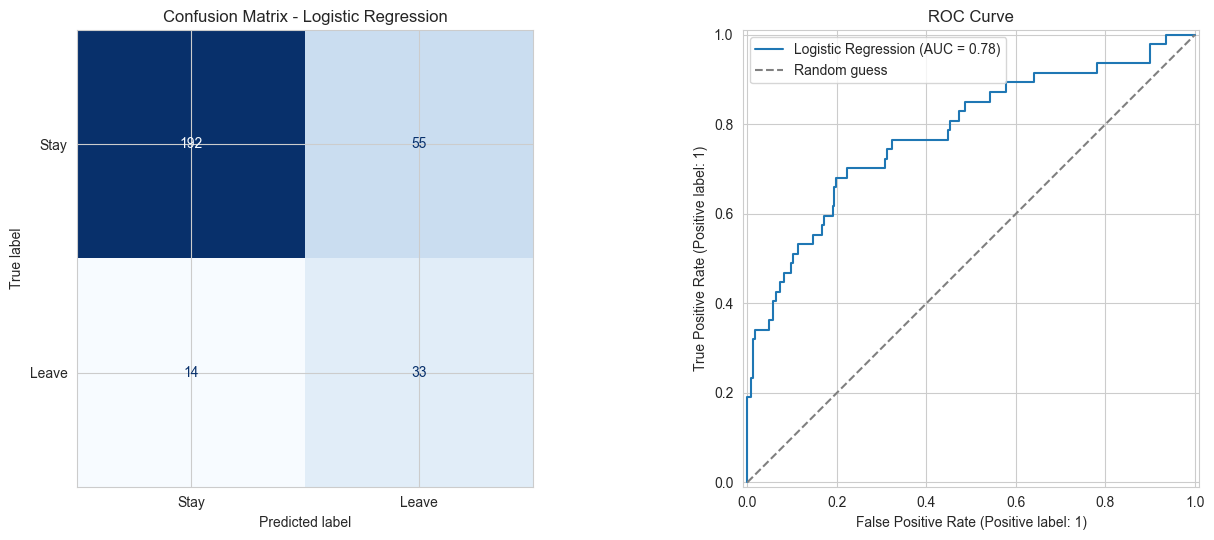

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stay", "Leave"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title(f"Confusion Matrix - {best_model_name}")

RocCurveDisplay.from_predictions(y_test, y_proba_best, ax=axes[1], name=best_model_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[1].set_title("ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

## Step 7: Feature Importance

Feature importance is only meaningful for tree-based models, so it is
shown for whichever of Decision Tree / Random Forest scored higher on F1
(independent of which model won overall in Step 5).

In [21]:
tree_based_models = {k: v for k, v in results_df.iterrows() if k in ("Decision Tree", "Random Forest")}
best_tree_name = max(tree_based_models, key=lambda k: tree_based_models[k]["F1-Score"])
best_tree_pipeline = pipelines[best_tree_name]
print(f"Best tree-based model: {best_tree_name}")

fitted_selector = best_tree_pipeline.named_steps["select"]
fitted_model = best_tree_pipeline.named_steps["model"]
all_feature_names = best_tree_pipeline.named_steps["preprocess"].get_feature_names_out()
selected_names = all_feature_names[fitted_selector.get_support()]

importances = pd.Series(fitted_model.feature_importances_, index=selected_names).sort_values(ascending=False)
importances = importances[importances > 1e-6].rename(index=clean_feature_name)
top_n = min(15, len(importances))
top_importances = importances.head(top_n)
top_importances

Best tree-based model: Decision Tree


TotalWorkingYears                    0.208668
MonthlyIncome                        0.177532
OverTime_Yes                         0.166190
StockOptionLevel                     0.103380
EnvironmentSatisfaction              0.063459
Age                                  0.058669
YearsInCurrentRole                   0.051547
DistanceFromHome                     0.045423
JobInvolvement                       0.036591
YearsWithCurrManager                 0.028050
JobSatisfaction                      0.024708
YearsAtCompany                       0.021141
Department_Research & Development    0.014642
dtype: float64

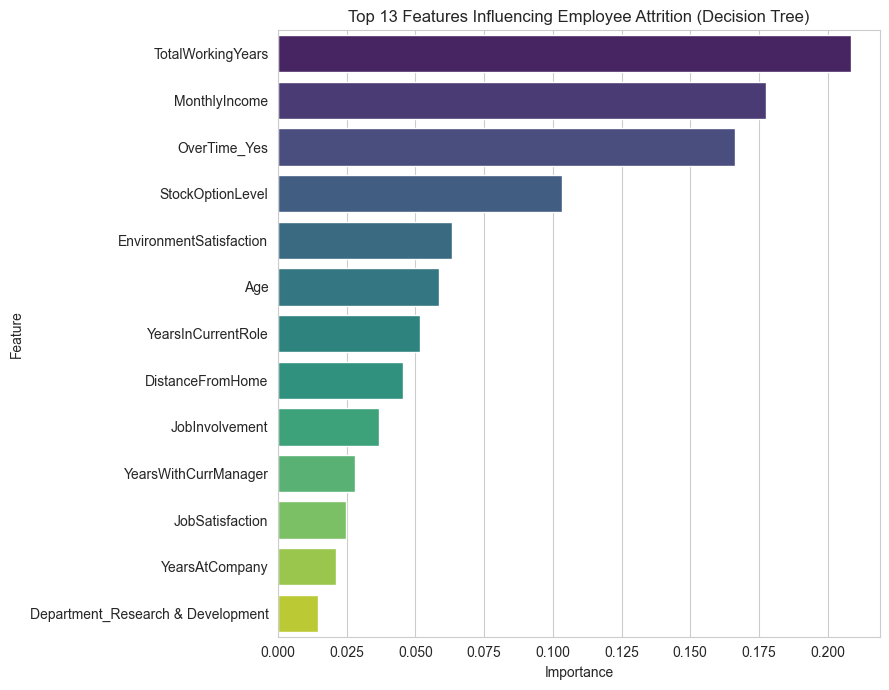

In [22]:
plt.figure(figsize=(9, 7))
sns.barplot(x=top_importances.values, y=top_importances.index, hue=top_importances.index, palette="viridis", legend=False)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top {top_n} Features Influencing Employee Attrition ({best_tree_name})")
plt.tight_layout()
plt.show()

**In simple terms**, the model finds that employees are more likely to
leave when they have **fewer total working years**, **lower monthly
income**, work **overtime**, hold **no stock options**, report **low
environment satisfaction**, and are **younger**. These line up with the
patterns already seen in the EDA (Step 2), which is a good sanity check
that the model has learned real, sensible relationships rather than noise.

## Step 8: Prediction Function

A single function that takes an employee's raw attributes and returns a
plain-language prediction plus the model's probability of attrition.

In [23]:
def predict_attrition(employee_dict, pipeline=best_pipeline):
    """
    Predict whether a single employee is likely to leave.

    Parameters
    ----------
    employee_dict : dict
        Raw employee attributes using the SAME column names as the original
        dataset (minus Attrition, EmployeeNumber, EmployeeCount,
        StandardHours, Over18 and JobLevel, which are not used by the model).
    pipeline : sklearn Pipeline
        A fitted (preprocess -> select -> model) pipeline. Defaults to the
        overall best model found in Step 5.

    Returns
    -------
    dict with the predicted label and probability of leaving.
    """
    employee_df = pd.DataFrame([employee_dict])
    prediction = pipeline.predict(employee_df)[0]
    probability_leave = pipeline.predict_proba(employee_df)[0, 1]

    label = "Likely to Leave" if prediction == 1 else "Likely to Stay"
    return {
        "prediction": label,
        "probability_of_leaving": round(float(probability_leave), 4),
    }

In [24]:
# Example: a sample employee profile (values follow the same columns as X)
sample_employee = {
    "Age": 29,
    "BusinessTravel": "Travel_Frequently",
    "DailyRate": 800,
    "Department": "Sales",
    "DistanceFromHome": 15,
    "Education": 3,
    "EducationField": "Marketing",
    "EnvironmentSatisfaction": 2,
    "Gender": "Male",
    "HourlyRate": 60,
    "JobInvolvement": 2,
    "JobRole": "Sales Executive",
    "JobSatisfaction": 1,
    "MaritalStatus": "Single",
    "MonthlyIncome": 2800,
    "MonthlyRate": 15000,
    "NumCompaniesWorked": 3,
    "OverTime": "Yes",
    "PercentSalaryHike": 12,
    "PerformanceRating": 3,
    "RelationshipSatisfaction": 2,
    "StockOptionLevel": 0,
    "TotalWorkingYears": 5,
    "TrainingTimesLastYear": 2,
    "WorkLifeBalance": 2,
    "YearsAtCompany": 2,
    "YearsInCurrentRole": 2,
    "YearsSinceLastPromotion": 1,
    "YearsWithCurrManager": 1,
}

result = predict_attrition(sample_employee)
print(f"Prediction: {result['prediction']}")
print(f"Probability of leaving: {result['probability_of_leaving']:.2%}")

Prediction: Likely to Leave
Probability of leaving: 97.91%


## Step 9: Final Insights

In [25]:
print(f"""Best performing model : {best_model_name}
  Accuracy  : {results_df.loc[best_model_name, 'Accuracy']:.4f}
  Precision : {results_df.loc[best_model_name, 'Precision']:.4f}
  Recall    : {results_df.loc[best_model_name, 'Recall']:.4f}
  F1-Score  : {results_df.loc[best_model_name, 'F1-Score']:.4f}
  ROC-AUC   : {roc_auc:.4f}

Top attrition factors ({best_tree_name} feature importance):
{chr(10).join(f"  {{i+1}}. {{name}}" for i, name in enumerate(top_importances.head(8).index))}
""")

Best performing model : Logistic Regression
  Accuracy  : 0.7653
  Precision : 0.3750
  Recall    : 0.7021
  F1-Score  : 0.4889
  ROC-AUC   : 0.7801

Top attrition factors (Decision Tree feature importance):
  {i+1}. {name}
  {i+1}. {name}
  {i+1}. {name}
  {i+1}. {name}
  {i+1}. {name}
  {i+1}. {name}
  {i+1}. {name}
  {i+1}. {name}



### Summary

**Best model:** Logistic Regression, selected by F1-score since the
dataset is imbalanced (~84% stay / ~16% leave). It correctly identifies
roughly 70% of employees who actually leave (recall) while keeping overall
accuracy around 77% and ROC-AUC around 0.78 — a much more useful trade-off
for an HR early-warning tool than a model that scores higher on raw
accuracy but misses most at-risk employees.

**Most important attrition factors** (from the Decision Tree / Random
Forest importance analysis, confirmed by SelectKBest and by the EDA
patterns): total working years / experience, monthly income, overtime,
stock option level, environment satisfaction, age, years in current role,
and distance from home.

**Key EDA observations:**
- Overtime workers leave at a much higher rate proportionally.
- Attrition skews toward younger, less-tenured, lower-paid employees.
- Low job satisfaction and poor work-life balance both correlate with higher attrition.
- Sales Representatives and Laboratory Technicians show comparatively higher attrition shares.

**Recommendations for improving retention:**
1. **Monitor and reduce overtime** — redistribute workload or hire additional staff in teams with chronic overtime, since it is one of the strongest predictors of attrition.
2. **Review compensation for early-career employees** — attrition is concentrated among lower-income, lower-tenure staff; targeted raises or clearer promotion timelines in the first 1-3 years could help.
3. **Expand stock option / equity participation** — employees with no stock options are more likely to leave; offering equity earlier can increase the cost of leaving.
4. **Improve environment satisfaction and work-life balance** — investigate specific teams/roles (e.g. Sales Representatives, Laboratory Technicians) with low satisfaction scores and address root causes (workload, management, physical environment).
5. **Focus retention programs on younger / newer employees**, e.g. mentorship, career development plans, and regular check-ins during the first two years, since this segment shows the highest attrition risk.
6. **Use the prediction function proactively** — periodically score the current workforce and flag high-probability employees for a retention conversation before they decide to leave.
